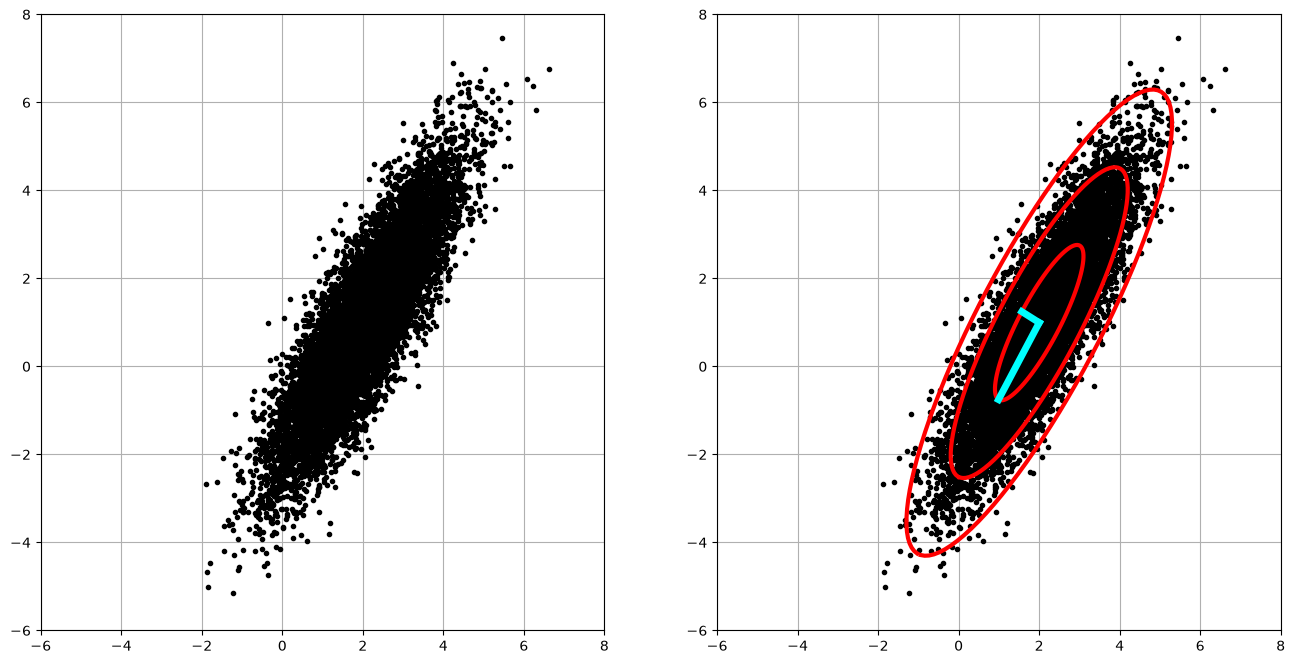

In [ ]:
'''
[YouTube - Steve Brunton - Principal Component Analysis (PCA) 1](https://www.youtube.com/watch?v=Oi4SJqJIL2E&list=PLMrJAkhIeNNSVjnsviglFoY2nXildDCcv&index=24)
'''
import numpy as np
import matplotlib.pyplot as plt

X_center = np.array([2, 1])
sig = np.array([2, 0.5])

theta = np.pi/3
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta), np.cos(theta)]])

nPoints = 10000
X = R @ np.diag(sig) @ np.random.randn(2, nPoints) + np.diag(X_center) @ np.ones((2, nPoints))

fig = plt.figure(figsize=(16, 8))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(X[0,:], X[1,:], '.', color='k')
ax1.grid()
plt.xlim((-6, 8))
plt.ylim((-6, 8))

X_avg = X.mean(axis=1)
B = X - np.diag(X_avg) @ np.ones((2, nPoints))
U, S, VT = np.linalg.svd(B/np.sqrt(nPoints), full_matrices=False)

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(X[0,:], X[1,:], '.', color='k')
ax2.grid()
plt.xlim((-6, 8))
plt.ylim((-6, 8))

theta = 2 * np.pi * np.arange(0, 1, 0.01)

# 1-std confidence interval
X_std = U @ np.diag(S) @ np.array([np.cos(theta), np.sin(theta)])

ax2.plot(X_avg[0] + X_std[0, :], X_avg[1] + X_std[1, :], '-', color="r", linewidth=3)
ax2.plot(X_avg[0] + 2*X_std[0, :], X_avg[1] + 2*X_std[1, :], '-', color="r", linewidth=3)
ax2.plot(X_avg[0] + 3*X_std[0, :], X_avg[1] + 3*X_std[1, :], '-', color="r", linewidth=3)

ax2.plot(np.array([X_avg[0], X_avg[0]+U[0,0]*S[0]]),
         np.array([X_avg[1], X_avg[1]+U[1,0]*S[0]]), '-', color='cyan', linewidth=5)
ax2.plot(np.array([X_avg[0], X_avg[0]+U[0,1]*S[1]]),
         np.array([X_avg[1], X_avg[1]+U[1,1]*S[1]]), '-', color='cyan', linewidth=5)
plt.show()

[[1.99363324 0.97958796]
 [1.99363324 0.97958796]
 [1.99363324 0.97958796]]
